# 02 · EMT-TF Expression — Chen 2020 NPC (malignant)

The EMT-transcription-factor overlay is the **unconditional** final step (§2), produced regardless
of how far the gate chain ran. **Gate 1 was a NO-GO** — the malignant compartment segregates by
patient rather than forming a sample-integrated continuous manifold — so no trajectory exists and
this notebook renumbers to **02**. It overlays the *detectable* EMT-TFs on the preprocessing
embedding for reference, without asserting any hub/arm structure.

**Panel selection (evaluation lesson 5).** Score a candidate panel spanning the canonical
Snail/Zeb/Twist factors **and** the mesenchymal FOXC/PRRX families, gate on a 3% detection floor,
and rank survivors by detection. On this dataset the canonical **SNAI1 (1.6%) and TWIST1 (1.0%)
fall below the floor**, while **PRRX1 (62%), SNAI2, FOXC1** are the strongest EMT-TFs — exactly the
Kürten pattern (FOXC/PRRX, not Snail/Twist).

In [1]:
import os, sys, re
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import warnings, logging; warnings.filterwarnings('ignore'); logging.disable(logging.INFO)
sc.settings.verbosity = 0

In [2]:
cwd = os.getcwd()
name = os.path.split(cwd)[1]
category = os.path.split(os.path.split(cwd)[0])[1]
pth = os.path.join('..', '..', '..', '..')
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', category, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', category, name)
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
raw = adata.raw.to_adata()   # log1p, all genes
print(adata.shape, '| Gate 1 = NO-GO (patient-segregated); overlay is for reference only')

(3674, 1290) | Gate 1 = NO-GO (patient-segregated); overlay is for reference only


### Detection-gated EMT-TF panel

In [3]:
candidates = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2',
              'PRRX1','PRRX2','TCF3','TCF4','SOX9','TEAD1','ETS1']
present = [g for g in candidates if g in raw.var_names]
X = raw[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
det = (X>0).mean(0)
tab = pd.DataFrame({'gene':present,'detect_frac':det.round(3),
                    'mean_in_pos':np.divide(X.sum(0),(X>0).sum(0),out=np.zeros(len(present)),where=(X>0).sum(0)>0).round(3)})
tab = tab.sort_values('detect_frac', ascending=False).reset_index(drop=True)
FLOOR = 0.03
tab['pass'] = tab.detect_frac >= FLOOR
print(tab.to_string(index=False))
below = tab[~tab['pass']].gene.tolist()
print(f'\nbelow {FLOOR:.0%} floor (excluded): {below}')
panel = tab[tab['pass']].gene.tolist()[:4]
print(f'top detectable EMT-TFs shown: {panel}')

  gene  detect_frac  mean_in_pos  pass
 PRRX1        0.623        0.571  True
  TCF4        0.516        0.347  True
  TCF3        0.401        0.255  True
  SOX9        0.308        0.258  True
 TEAD1        0.246        0.247  True
 SNAI2        0.244        0.296  True
  ETS1        0.162        0.303  True
 FOXC1        0.133        0.239  True
  ZEB2        0.130        0.177  True
  ZEB1        0.073        0.152  True
TWIST2        0.059        0.230  True
 FOXC2        0.043        0.249  True
 PRRX2        0.023        0.243 False
 SNAI1        0.016        0.150 False
TWIST1        0.010        0.330 False

below 3% floor (excluded): ['PRRX2', 'SNAI1', 'TWIST1']
top detectable EMT-TFs shown: ['PRRX1', 'TCF4', 'TCF3', 'SOX9']


### Detection ranking bar

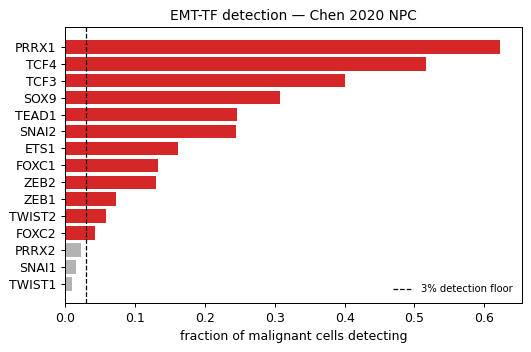

In [4]:
fig, ax = plt.subplots(figsize=(6,4))
colors = ['tab:red' if p else '0.7' for p in tab['pass']]
ax.barh(tab.gene[::-1], tab.detect_frac[::-1], color=colors[::-1])
ax.axvline(FLOOR, ls='--', color='k', lw=1, label=f'{FLOOR:.0%} detection floor')
ax.set_xlabel('fraction of malignant cells detecting'); ax.set_title('EMT-TF detection — Chen 2020 NPC', size=11)
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); plt.show()

### Expression overlay on the (patient-segregated) embedding

Top detectable EMT-TFs overlaid on the UMAP. With Gate 1 a NO-GO the layout reflects patient
territories, so this is a reference readout of *where* the mesenchymal factors are expressed, not a
trajectory. `expression.pdf` is the deliverable figure.

saved expression.pdf | panel: ['PRRX1', 'TCF4', 'TCF3', 'SOX9']


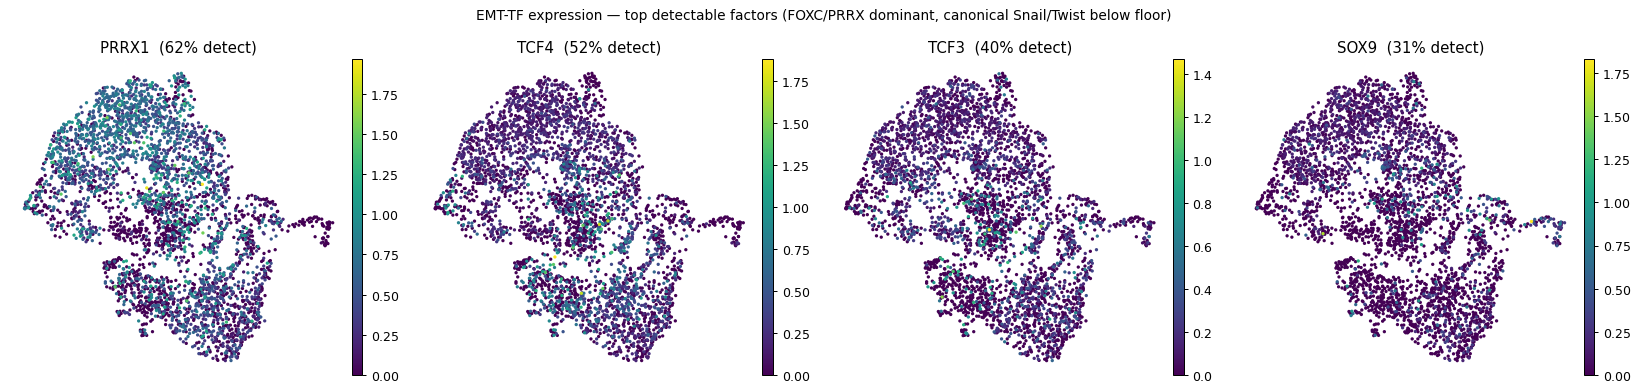

In [5]:
fig, axes = plt.subplots(1, len(panel), figsize=(4.6*len(panel), 4.4))
if len(panel)==1: axes=[axes]
detmap = tab.set_index('gene').detect_frac
for ax,g in zip(axes,panel):
    col = f'expr_{g}'
    xg = raw[:,g].X
    adata.obs[col] = np.asarray(xg.todense()).ravel() if hasattr(xg,'todense') else np.asarray(xg).ravel()
    sc.pl.umap(adata, color=col, ax=ax, show=False, size=28, frameon=False,
               title=f'{g}  ({detmap[g]:.0%} detect)', cmap='viridis')
fig.suptitle('EMT-TF expression — top detectable factors (FOXC/PRRX dominant, canonical Snail/Twist below floor)', size=11)
fig.tight_layout()
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
print('saved expression.pdf | panel:', panel)